# Análisis del GRB 251118A con Fermi-LAT

Este cuaderno presenta el análisis del GRB 251118A con datos del Fermi-LAT, siguiendo el flujo
estándar de Fermitools (el mismo que se valida primero con el GRB 080916C, el caso del tutorial
oficial). Cada paso lleva su justificación: los conceptos se definen antes de usarse (IRF, boresight,
TS, GALPROP), cada corte va con su valor, la curva de luz cubre una ventana larga para medir el nivel
de fondo, la compatibilidad de cada fotón con la posición del GRB se evalúa contra la PSF, los
residuos espectrales van normalizados por su incertidumbre, cada ajuste reporta sus normalizaciones y
grados de libertad, y al final los resultados *binned* y *unbinned* se comparan entre sí y con la
circular GCN.

**Lo que reportó cada instrumento** (las 12 circulares GCN del evento):

| Instrumento (GCN) | Qué midió |
|---|---|
| Fermi GBM, loc. autom. ([42743](https://gcn.nasa.gov/circulars/42743)) | Disparo a las 20:31:30.09 UT del 18 nov 2025 (trigger 785190695 / 251118855) = **T0 = 785190695.09 s (MET)**. Posición automática RA 160.4, Dec −36.5 (±1.0°) |
| BALROG ([42745](https://gcn.nasa.gov/circulars/42745)) | RA 160.0, Dec −34.9 (±2° estad. + ~2° sist.) |
| Swift ToO ([42750](https://gcn.nasa.gov/circulars/42750)) | Aprobación del seguimiento con Swift |
| **Fermi-LAT ([42752](https://gcn.nasa.gov/circulars/42752))** | RA 160.08, Dec −34.58 (±0.17°, 90 %); a **69° del boresight** en T0; flujo (>100 MeV, 0–1.5 ks) = (1.8 ± 0.7)×10⁻⁶ ph cm⁻² s⁻¹; índice fotónico −1.8 ± 0.3; fotón de **6.8 GeV a ~1400 s** |
| NuSTAR ([42774](https://gcn.nasa.gov/circulars/42774)) | Detección de la emisión prompt brillante |
| GECAM-B ([42779](https://gcn.nasa.gov/circulars/42779)) | T90 = 46.2 s; corte exp. con Epeak ≈ 99.8 keV; fluencia (10–1000 keV) ≈ 1.01×10⁻⁴ erg cm⁻² |
| **Swift-XRT ([42782](https://gcn.nasa.gov/circulars/42782))** | **Afterglow en rayos X** en RA 160.00418, Dec −34.52259 (±2″), a 5.0′ de la posición LAT; decaimiento t^−1.08; índice fotónico X 1.73 |
| **Fermi GBM ([42783](https://gcn.nasa.gov/circulars/42783))** | **T90 = 46.6 s** (50–300 keV); fluencia (10–1000 keV) = (1.03 ± 0.01)×10⁻⁴ erg cm⁻² (¡un GRB brillante!); Band: Epeak = 134.0 ± 2.7 keV, α = −1.36, **β = −2.56 ± 0.06**; flujo pico 96 ph cm⁻² s⁻¹ (1 s) |
| Glowbug ([42784](https://gcn.nasa.gov/circulars/42784)) | Detección en gamma |
| **Swift/UVOT ([42786](https://gcn.nasa.gov/circulars/42786))** | **Afterglow óptico** en RA 160.00422, Dec −34.52254 (**±0.42″**); white 18.79 → 20.11 en dos épocas |
| Konus-Wind ([43013](https://gcn.nasa.gov/circulars/43013)) | Precursor desde T0−20.5 s; episodio principal T0+33 a T0+65 s; fluencia (20 keV–10 MeV) = 1.07×10⁻⁴ erg cm⁻²; Band del episodio principal: Ep = 154 keV, α = −1.29, β = −2.56 |
| TERI ([44680](https://gcn.nasa.gov/circulars/44680)) | Detección en gamma (may 2026) |

Sin corrimiento al rojo reportado. Tres consecuencias directas para el análisis:

1. **La posición del GRB se conoce a 0.42″** gracias al afterglow de UVOT: esa es la posición que usamos
   para la fuente puntual y para las separaciones angulares (no la del LAT, cuya incertidumbre es 0.17°).
2. **El prompt en keV terminó en ~47 s** (T90 del GBM; episodios hasta T0+87 s según el intervalo del
   ajuste del GBM). Los fotones del LAT entre 400 y 1500 s llegan **mucho después del prompt**: son
   emisión extendida/afterglow de alta energía, y la curva de luz lo va a mostrar con el T90 sombreado.
3. **Epeak ≈ 134–154 keV**, cinco órdenes por debajo de la banda del LAT: lo que el LAT ve es la cola de
   alta energía, y eso justifica modelarla con una ley de potencia simple. Además el índice LAT
   (−1.8 ± 0.3) es más duro que la β de Band del GBM (−2.56 ± 0.06): un indicio (con la cautela de las
   incertidumbres) de que la emisión GeV no es la simple extrapolación del prompt.

El **boresight** es el eje óptico del LAT (la normal al plano superior del instrumento). A 69° del
boresight el área efectiva cae mucho —el campo de visión útil llega a ~70°—, y eso, de entrada, explica
el bajo número de fotones detectados pese a lo brillante del GRB en keV.

> **Aclaración de nomenclatura:** la página de eventos `EP251118a` de GCN corresponde a **otro evento**
> (el transitorio EP251118a / GRB 251118**C** de Einstein Probe, en RA 123.2°, Dec +11.0°, con T0
> 16:44 UT). Nuestro GRB 251118**A** es el del disparo GBM 785190695 de las 20:31 UT, reportado por el
> LAT en la circular [GCN 42752](https://gcn.nasa.gov/circulars/42752). No hay que mezclar sus números.

**Etapas:**

1. Descarga y preparación de los datos (FT1 y FT2) y parámetros del análisis.
2. Las funciones de respuesta del instrumento (IRF) y las clases de eventos.
3. Selección de eventos (`gtselect`) y depuración de intervalos (`gtmktime`).
4. Curva de luz larga (`gtbin LC` + Python) y nivel de fondo.
5. Fotones individuales: PSF contra separación angular, y conteos por radio de extracción.
6. Mapa de conteos (`gtbin CMAP`) y verificación de la posición.
7. Modelo de la región de interés (XML) y exposición (`gtdiffrsp`, `gtltcube`, `gtexpmap`).
8. Ajuste unbinned (`gtlike`): modelo base y modelo con fondo galáctico fijo.
9. Análisis binned (`gtbin PHA1`, `gtrspgen`, XSPEC).
10. Comparación binned vs. unbinned vs. GCN y conclusiones.

> **Antes de empezar:** activar el entorno de Fermitools (`conda activate fermi`) y abrir Jupyter desde ahí.


## 1. Descarga y preparación de los datos

Los datos se piden en el
[LAT Data Server](https://fermi.gsfc.nasa.gov/cgi-bin/ssc/LAT/LATDataQuery.cgi) con estos parámetros
(la consulta es solo un **recorte grueso** del archivo de la misión: un cono espacial y una ventana de
tiempo y energía; los cortes finos de clase, calidad y ángulo cenital los hacen después `gtselect` y
`gtmktime` — esa es la diferencia entre «bajar los datos» y «seleccionarlos»):

| Parámetro de la consulta | Valor | Por qué |
|---|---|---|
| Centro (RA, Dec) | (160.08, −34.58) | posición LAT de la GCN 42752 |
| Radio de búsqueda | 30° | mayor que la ROI del análisis (15°), para poder probar ROIs más grandes |
| Inicio (MET) | 785189695 (= T0 − 1000 s) | fondo antes del estallido |
| Fin (MET) | 785194395 (= T0 + 3700 s) | ~1 h después, para ver el nivel de fondo tras la emisión |
| Energía | 100 a 300000 MeV | banda estándar del análisis del LAT |
| Tipo de datos | **Extended** | incluye todas las clases de eventos (la clase se elige después, en `gtselect`) |

El servidor entrega dos archivos: el de **eventos** (fotones, `_EV00`) y el de la **nave**
(*spacecraft*, `_SC00`), con la orientación del telescopio cada 30 s. **Pega abajo las URL de tu
consulta** (las `L...._EV00.fits` y `L...._SC00.fits` que te dé el servidor); se descargan ya
renombrados como `FT1.fits` (eventos) y `FT2.fits` (nave), y la celda no vuelve a bajarlos si ya están.


In [1]:
%%bash
mkdir -p data
# >>> PEGA AQUÍ LAS URL DE TU CONSULTA (sustituye L00000000000000000000_EV00/_SC00) <<<
URL_EV="https://fermi.gsfc.nasa.gov/FTP/fermi/data/lat/queries/L261112090131FD70614168_EV00.fits"
URL_SC="https://fermi.gsfc.nasa.gov/FTP/fermi/data/lat/queries/L261112090131FD70614168_SC00.fits"

[ -f data/FT1.fits ] || wget -O data/FT1.fits "$URL_EV"   # FT1 = eventos (fotones)
[ -f data/FT2.fits ] || wget -O data/FT2.fits "$URL_SC"   # FT2 = nave (spacecraft)
ls -lh data/

[0] Downloading 'https://fermi.gsfc.nasa.gov/FTP/fermi/data/lat/queries/L261112090131FD70614168_EV00.fits' ...
Saving 'data/FT1.fits'
HTTP response 200 OK [https://fermi.gsfc.nasa.gov/FTP/fermi/data/lat/queries/L261112090131FD70614168_EV00.fits]
[0] Downloading 'https://fermi.gsfc.nasa.gov/FTP/fermi/data/lat/queries/L261112090131FD70614168_SC00.fits' ...
Saving 'data/FT2.fits'
HTTP response 200 OK [https://fermi.gsfc.nasa.gov/FTP/fermi/data/lat/queries/L261112090131FD70614168_SC00.fits]
total 228K
-rw-r--r--. 1 fabriciooos fabriciooos 178K nov 12 08:01 FT1.fits
-rw-r--r--. 1 fabriciooos fabriciooos  45K nov 12 08:01 FT2.fits


### Verificación y parámetros del análisis

Confirmamos qué trae la consulta y dejamos **en un solo lugar** todos los parámetros, como variables de
entorno que las celdas `%%bash` leen con `$NOMBRE`. Dos ventanas distintas:

- **Ventana larga** (T0 − 100 a T0 + 3600 s): solo para la curva de luz, para ver cuándo se apaga la
  emisión y cuál es el nivel de fondo (con una ventana corta no se alcanza a ver el
  «vacío» posterior al apagado de la fuente).
- **Ventana de análisis** (T0 a T0 + 1500 s): la misma que usó la circular GCN para el flujo
  (0–1.5 ks), de modo que nuestro flujo y el suyo sean directamente comparables.

La **ROI del análisis es de 15°**. Con tan pocos fotones no conviene achicarla
para «limpiar» la región: quitar área también quita señal y agranda el error del flujo; si acaso,
tiene más sentido probar una ROI mayor.

Como **posición del GRB** se usa la del afterglow de Swift/UVOT (RA 160.00422, Dec −34.52254, ±0.42″,
GCN 42786): con esa precisión, la incertidumbre de posición es despreciable frente a la PSF del LAT y ya
no hace falta `gtfindsrc`. La posición del LAT (160.08, −34.58, ±0.17°) queda como referencia: está a
~5′ del afterglow, consistente con su radio de error.


In [2]:
import os
from astropy.io import fits

with fits.open('data/FT1.fits') as f:
    ev = f['EVENTS']
    print(f"Eventos en la consulta : {ev.header['NAXIS2']}")
    print(f"Ventana de la consulta : MET {ev.header['TSTART']:.1f} a {ev.header['TSTOP']:.1f}"
          f"  ({ev.header['TSTOP']-ev.header['TSTART']:.0f} s)")

T0 = 785190695.09   # disparo del GBM (MET), GCN 42752

os.environ.update({
    'T0':      f'{T0:.2f}',
    'RA_GRB':  '160.00422',         # afterglow Swift/UVOT, ±0.42" (GCN 42786)
    'DEC_GRB': '-34.52254',
    'RA_LAT':  '160.08',            # posición LAT ±0.17° (GCN 42752), solo de referencia
    'DEC_LAT': '-34.58',
    'T90':     '46.6',              # T90 del GBM en 50-300 keV (GCN 42783)
    'ROI':     '15',                # radio de la región de interés, en grados
    'TLC1':    f'{T0-100:.2f}',     # ventana larga (curva de luz): T0-100 a T0+3600
    'TLC2':    f'{T0+3600:.2f}',
    'TAN1':    f'{T0:.2f}',         # ventana de análisis: T0 a T0+1500 (la de la GCN)
    'TAN2':    f'{T0+1500:.2f}',
    'EMIN':    '100',               # MeV
    'EMAX':    '300000',            # MeV
    'ZMAX':    '100',               # corte en ángulo cenital, en grados
})
print('\nParámetros:', {k: os.environ[k] for k in
      ['T0','RA_GRB','DEC_GRB','T90','ROI','TLC1','TLC2','TAN1','TAN2','EMIN','EMAX','ZMAX']})

Eventos en la consulta : 700
Ventana de la consulta : MET 785189695.0 a 785194395.0  (4700 s)

Parámetros: {'T0': '785190695.09', 'RA_GRB': '160.00422', 'DEC_GRB': '-34.52254', 'T90': '46.6', 'ROI': '15', 'TLC1': '785190595.09', 'TLC2': '785194295.09', 'TAN1': '785190695.09', 'TAN2': '785192195.09', 'EMIN': '100', 'EMAX': '300000', 'ZMAX': '100'}


## 2. Las IRF y las clases de eventos (antes de usarlas)

Todo el análisis se apoya en las **funciones de respuesta del instrumento** (*Instrument Response
Functions*, IRF), que describen cómo responde el LAT a un fotón incidente y tienen tres partes:

- el **área efectiva** (cm²) en función de la energía y del ángulo de incidencia,
- la **PSF** (*point spread function*): la dispersión de la dirección reconstruida,
- la **dispersión en energía**: la diferencia entre la energía reconstruida y la verdadera.

Cada **clase de eventos** tiene su propia IRF, porque los cortes de reconstrucción cambian la respuesta:

| Clase | `evclass` | IRF | Uso |
|---|---|---|---|
| `TRANSIENT020` | 16 | `P8R3_TRANSIENT020_V3` | fase prompt de GRBs cortos y débiles: máxima sensibilidad, más contaminación de rayos cósmicos y de fotones producidos en la propia nave |
| `SOURCE` | 128 | `P8R3_SOURCE_V3` | más estricta en la discriminación del fondo; adecuada para emisión de cientos de segundos, como la de este GRB |

El GRB 251118A se detectó como **emisión extendida** (los fotones llegan repartidos a lo largo de
~1.5 ks, no en un pico corto), así que todo el análisis usa la clase `SOURCE` con `P8R3_SOURCE_V3`.
Las IRF aparecerán en `gtdiffrsp`, `gtexpmap`, `gtrspgen` (vía CALDB) y `gtlike`: siempre la misma.

## 2b. El verdadero reto de este análisis: pocos fotones

El tutorial de Fermitools funciona «a la primera» porque su caso de estudio, el GRB 080916C, es uno de
los más brillantes que el LAT ha registrado: cientos de fotones en 40 segundos, con los que cualquier
método converge. El GRB 251118A es el caso opuesto —y por eso es el caso instructivo—: aunque en keV fue
un GRB brillante (fluencia GBM de 1.03×10⁻⁴ erg/cm²), al LAT llegó a 69° del boresight y con un flujo
GeV modesto, así que en toda la ventana de 1500 s se esperan solo **unas pocas decenas de fotones en la
ROI, de los cuales el modelo atribuye ~8 al GRB**. Ese número condiciona cada decisión
del análisis, y conviene tener sus consecuencias enfrente desde el inicio:

| Consecuencia de tener pocos fotones | Qué se hace en este cuaderno |
|---|---|
| Agrupar en bins desperdicia información | El ajuste principal es **unbinned** (fotón por fotón); el binned de XSPEC queda como control cruzado (secc. 8 y 9) |
| El ajuste no soporta muchos parámetros libres: la matriz de covarianza deja de ser definida positiva y los fondos pueden «absorber» señal del GRB | Isotrópico fijo en catálogo; **cuatro variantes V1–V4** del modelo (qué se fija y qué se libera), con normalizaciones y grados de libertad reportados (secc. 7–8) |
| El χ² y su «probabilidad nula» pierden sentido (canales con 0–2 conteos) | Estadístico **C-stat** y bondad por simulación (`goodness`); la probabilidad nula de χ² se descarta explícitamente (secc. 9) |
| El fondo pesa: si se esperan ~8 fotones del GRB, el resto de la ROI es fondo | Se **mide** la tasa de fondo en la cola de la ventana larga y se compara con Npred (secc. 4 y 8) |
| σ ≈ √TS (Wilks) es solo aproximado con tan poca estadística, y comparar TS exige mismos grados de libertad | Se reporta TS con sus grados de libertad y la significancia como aproximación, no como medida exacta (secc. 8) |
| Los errores del flujo salen grandes y asimétricos; «consistente con la GCN» hay que demostrarlo | La comparación final se hace en **σ combinadas**, no a ojo (secc. 10) |
| Achicar la ROI para «limpiar» elimina señal y dispara el error del flujo | ROI de 15° y, si acaso, probar hacia **arriba**, no hacia abajo |


## 3. Selección de eventos y depuración de intervalos

### 3a. `gtselect`

Aplica sobre el FT1 los cortes que la descarga no hizo: clase de eventos (`evclass=128`), cono de 15°
alrededor del GRB, ventana temporal, banda de energía y el corte en ángulo cenital **`zmax=100°`**, que
elimina los fotones del limbo de la Tierra (la atmósfera brilla en gamma por los rayos cósmicos que la
golpean). Hacemos dos selecciones: la de la ventana larga (para la curva de luz) y la de la ventana de
análisis.


In [3]:
%%bash
# Selección de la ventana larga (solo para la curva de luz)
gtselect evclass=128 \
    infile=data/FT1.fits \
    outfile=data/lc_select.fits \
    ra=$RA_GRB dec=$DEC_GRB rad=$ROI \
    tmin=$TLC1 tmax=$TLC2 \
    emin=$EMIN emax=$EMAX \
    zmax=$ZMAX

Done.


In [4]:
%%bash
# Selección de la ventana de análisis (T0 a T0+1500 s, la de la GCN)
gtselect evclass=128 \
    infile=data/FT1.fits \
    outfile=data/analisis_select.fits \
    ra=$RA_GRB dec=$DEC_GRB rad=$ROI \
    tmin=$TAN1 tmax=$TAN2 \
    emin=$EMIN emax=$EMAX \
    zmax=$ZMAX

Done.


### 3b. `gtmktime`

Cruza los eventos con el FT2 y deja solo los **intervalos de buen tiempo** (GTI). El filtro
`(DATA_QUAL>0)&&(LAT_CONFIG==1)` es la **máscara estándar que recomienda el FSSC en el Cicerone**
(datos de buena calidad y el instrumento en su configuración científica normal); `roicut=yes` además
excluye los tiempos en que la ROI sale del campo de visión.


In [5]:
%%bash
gtmktime scfile=data/FT2.fits \
    filter="(DATA_QUAL>0)&&(LAT_CONFIG==1)" \
    roicut=yes \
    evfile=data/lc_select.fits \
    outfile=data/lc_mktime.fits

gtmktime scfile=data/FT2.fits \
    filter="(DATA_QUAL>0)&&(LAT_CONFIG==1)" \
    roicut=yes \
    evfile=data/analisis_select.fits \
    outfile=data/analisis_mktime.fits

In [6]:
# ¿Cuántos fotones quedaron y en qué radio? (siempre decir el radio al dar un conteo)
from astropy.io import fits
for nombre, archivo in [('ventana larga  (T0-100, T0+3600)', 'data/lc_mktime.fits'),
                        ('ventana GCN    (T0,     T0+1500)', 'data/analisis_mktime.fits')]:
    with fits.open(archivo) as f:
        n = f['EVENTS'].header['NAXIS2']
        gti = f['GTI'].data
        expo = (gti['STOP'] - gti['START']).sum()
    print(f"{nombre}: {n} fotones dentro de {os.environ['ROI']}°; GTI = {expo:.0f} s en {len(gti)} intervalo(s)")

ventana larga  (T0-100, T0+3600): 39 fotones dentro de 15°; GTI = 2512 s en 2 intervalo(s)
ventana GCN    (T0,     T0+1500): 35 fotones dentro de 15°; GTI = 1500 s en 1 intervalo(s)


## 4. Curva de luz larga y nivel de fondo

La curva de luz se construye con la herramienta de Fermitools (`gtbin` en modo `LC`, bins de 50 s) y se
grafica con Python en dos paneles: arriba los conteos por bin con una
marca por fotón, abajo la energía de cada fotón contra el tiempo, coloreada por su separación angular
al GRB.

La ventana llega hasta **T0 + 3600 s** para responder dos preguntas que una ventana corta no puede
responder: ¿cuántos fotones son de fondo?, y ¿se ve el «vacío» cuando el GRB se apaga?


In [7]:
%%bash
gtbin algorithm=LC \
    evfile=data/lc_mktime.fits \
    outfile=data/lc_251118A.fits \
    scfile=data/FT2.fits \
    tbinalg=LIN tstart=$TLC1 tstop=$TLC2 dtime=50

This is gtbin version HEAD


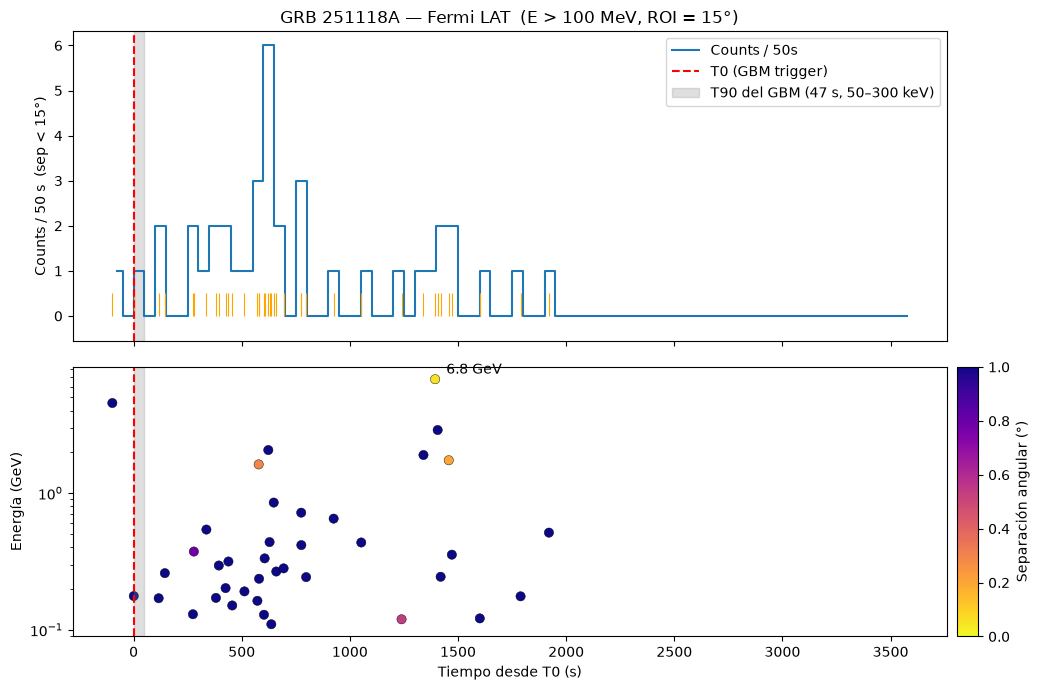

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from astropy.io import fits
from astropy.coordinates import SkyCoord
import astropy.units as u
import os

# Valores por defecto por si el kernel es nuevo y no se corrió la celda de parámetros:
T0 = float(os.environ.get('T0', 785190695.09))
ROI = os.environ.get('ROI', '15')
pos_grb = SkyCoord(float(os.environ.get('RA_GRB', 160.00422)),
                   float(os.environ.get('DEC_GRB', -34.52254)), unit='deg')

lc = fits.getdata('data/lc_251118A.fits', ext=1)          # TIME, TIMEDEL, COUNTS, ERROR
ev = fits.getdata('data/lc_mktime.fits', ext=1)           # eventos de la ventana larga
sep = SkyCoord(ev['RA'], ev['DEC'], unit='deg').separation(pos_grb).deg
t_ev = ev['TIME'] - T0

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10.5, 7), sharex=True,
                               gridspec_kw={'height_ratios': [1.15, 1]})

T90 = float(os.environ.get('T90', 46.6))

# Panel superior: conteos por bin de 50 s + una marca por fotón
ax1.step(lc['TIME'] - T0, lc['COUNTS'], where='mid', label='Counts / 50s')
ax1.eventplot(t_ev, lineoffsets=0.25, linelengths=0.5, colors='orange', lw=0.8)
ax1.axvline(0, color='red', ls='--', label='T0 (GBM trigger)')
ax1.axvspan(0, T90, color='gray', alpha=0.25, label=f'T90 del GBM ({T90:.0f} s, 50–300 keV)')
ax1.set_ylabel(f"Counts / 50 s  (sep < {ROI}°)")
ax1.set_title(f"GRB 251118A — Fermi LAT  (E > 100 MeV, ROI = {ROI}°)")
ax1.legend()

# Panel inferior: energía de cada fotón, color = separación angular al GRB
sc = ax2.scatter(t_ev, ev['ENERGY']/1000.0, c=np.clip(sep, 0, 1), cmap='plasma_r',
                 vmin=0, vmax=1, edgecolors='k', linewidths=0.3, s=45)
ax2.axvline(0, color='red', ls='--')
ax2.axvspan(0, T90, color='gray', alpha=0.25)
imax = np.argmax(ev['ENERGY'])
ax2.annotate(f"{ev['ENERGY'][imax]/1000:.1f} GeV", (t_ev[imax], ev['ENERGY'][imax]/1000.0),
             textcoords='offset points', xytext=(8, 4))
ax2.set_yscale('log')
ax2.set_xlabel('Tiempo desde T0 (s)')
ax2.set_ylabel('Energía (GeV)')
# La barra de color va en un eje aparte y arriba se reserva el mismo espacio,
# para que ambos paneles tengan exactamente el mismo ancho y eje de tiempo.
cax_arriba = make_axes_locatable(ax1).append_axes('right', size='2.5%', pad=0.1)
cax_arriba.axis('off')
cax = make_axes_locatable(ax2).append_axes('right', size='2.5%', pad=0.1)
fig.colorbar(sc, cax=cax, label='Separación angular (°)')
plt.tight_layout()
plt.savefig('data/LC_251118A_larga.png', dpi=150)
plt.show()

**Lectura de la curva de luz.** La banda gris es el **T90 del GBM (46.6 s)**: todo el prompt en
keV cabe ahí (Konus-Wind ubica el episodio principal entre T0+33 y T0+65 s, con un precursor desde
T0−20 s). Con eso a la vista, la emisión del LAT se describe sin adivinar: los fotones compatibles con
el GRB (separación pequeña, color claro) se concentran **agrupados entre ~400 y ~700 s**, con llegadas adicionales hasta ~1500 s (incluido el fotón de 6.8 GeV a ~1400 s,
anotado en la figura), es decir, **mucho después de que el prompt en keV terminó**: emisión
extendida/afterglow de alta energía, no la cola del prompt. Después la región queda en el nivel de
fondo. La celda siguiente cuantifica ese fondo con la parte tardía de la ventana (T0+2000 a T0+3600,
cuando el GRB ya se apagó):


In [10]:
# Nivel de fondo medido en la cola de la ventana (T0+2000 a T0+3600)
mask_fondo = (t_ev >= 2000) & (t_ev <= 3600)
# ¿cuánto tiempo bueno (GTI) hay en esa cola?
gti = fits.getdata('data/lc_mktime.fits', 'GTI')
t_gti = 0.0
for a, b in zip(gti['START'] - T0, gti['STOP'] - T0):
    t_gti += max(0.0, min(b, 3600) - max(a, 2000))
tasa_fondo = mask_fondo.sum() / t_gti if t_gti > 0 else float('nan')
esperados = tasa_fondo * 1500
print(f"Fotones en (T0+2000, T0+3600) dentro de {os.environ['ROI']}°: {mask_fondo.sum()} en {t_gti:.0f} s de GTI")
print(f"Tasa de fondo estimada: {tasa_fondo*1000:.2f} fotones por cada 1000 s")
print(f"Fondo esperado en la ventana de análisis (1500 s): ~{esperados:.1f} fotones")
print("(Si la cola cae fuera de los GTI, ampliar la consulta o estimar el fondo con otra órbita.)")

Fotones en (T0+2000, T0+3600) dentro de 15°: 0 en 412 s de GTI
Tasa de fondo estimada: 0.00 fotones por cada 1000 s
Fondo esperado en la ventana de análisis (1500 s): ~0.0 fotones
(Si la cola cae fuera de los GTI, ampliar la consulta o estimar el fondo con otra órbita.)


> **Nota honesta:** si el tiempo bueno en la cola es poco (el LAT pudo salir de la región por el
> *sky survey*), la tasa de fondo queda mal medida; en ese caso vale repetir la consulta con una ventana
> aún mayor. El punto metodológico se mantiene: **todo conteo de la ventana del estallido incluye
> fondo**, y hay que decir cuánto se espera antes de atribuirle fotones al GRB.

## 5. Fotones individuales: ¿cuáles son compatibles con el GRB?

### 5a. PSF contra separación angular, fotón por fotón

Para cada fotón de la ventana de análisis se grafica su **separación angular al GRB (Δr)** contra el
**radio de contención del 68 % de la PSF a su energía**. Δr se mide desde la posición del afterglow de
UVOT (±0.42″), así que la incertidumbre de posición no aporta nada a Δr: lo que quede lejos, lejos está.
Un fotón de verdad proveniente del GRB debe tener Δr comparable o menor que la PSF a su energía; uno de
fondo puede caer donde sea. El color indica la energía. (La PSF se aproxima con la parametrización de la página de
[rendimiento del LAT](https://www.slac.stanford.edu/exp/glast/groups/canda/lat_Performance.htm):
θ68(E) ≈ √[(3.3°·(E/100 MeV)⁻⁰·⁸)² + (0.05°)²], válida para la clase SOURCE a incidencia normal.)


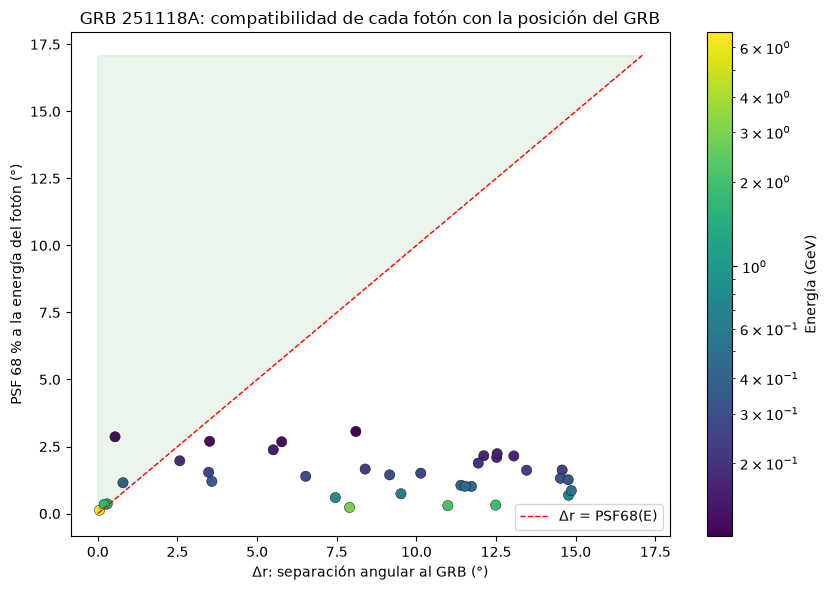

Fotones con Δr ≤ PSF68(E): 5 de 35 (ventana T0 a T0+1500, ROI 15°)
Fotón de mayor energía: 6.8 GeV a T0+1394 s, Δr = 0.052° (PSF68 a esa energía: 0.124°)


In [11]:
ev_an = fits.getdata('data/analisis_mktime.fits', ext=1)
sep_an = SkyCoord(ev_an['RA'], ev_an['DEC'], unit='deg').separation(pos_grb).deg
E_an = ev_an['ENERGY']                     # MeV
t_an = ev_an['TIME'] - T0

def psf68(E_MeV):
    """Contención del 68% (grados), aproximación P8R3_SOURCE a incidencia normal."""
    return np.sqrt((3.3*(E_MeV/100.0)**-0.8)**2 + 0.05**2)

fig, ax = plt.subplots(figsize=(8.5, 6))
sc = ax.scatter(sep_an, psf68(E_an), c=E_an/1000.0, cmap='viridis',
                norm=plt.matplotlib.colors.LogNorm(), edgecolors='k', linewidths=0.3, s=55)
lim = max(sep_an.max(), psf68(E_an).max()) * 1.15
ax.plot([0, lim], [0, lim], 'r--', lw=1, label='Δr = PSF68(E)')
ax.fill_between([0, lim], [0, lim], lim, alpha=0.08, color='green')
ax.set_xlabel('Δr: separación angular al GRB (°)')
ax.set_ylabel('PSF 68 % a la energía del fotón (°)')
ax.set_title('GRB 251118A: compatibilidad de cada fotón con la posición del GRB')
ax.legend(loc='lower right')
fig.colorbar(sc, ax=ax, label='Energía (GeV)')
plt.tight_layout()
plt.savefig('data/PSF_vs_dr_251118A.png', dpi=150)
plt.show()

compatibles = (sep_an <= psf68(E_an)).sum()
print(f"Fotones con Δr ≤ PSF68(E): {compatibles} de {len(ev_an)} (ventana T0 a T0+1500, ROI {os.environ['ROI']}°)")
imax = np.argmax(E_an)
print(f"Fotón de mayor energía: {E_an[imax]/1000:.1f} GeV a T0+{t_an[imax]:.0f} s, Δr = {sep_an[imax]:.3f}° "
      f"(PSF68 a esa energía: {psf68(E_an[imax]):.3f}°)")

Los fotones **arriba de la línea roja** (zona verde: Δr menor que la PSF) son posicionalmente
compatibles con el GRB; los de abajo, a muchas PSF de distancia, son casi con seguridad fondo. En
particular, el fotón de ~6.8 GeV a T0+~1400 s debe aparecer pegado al eje (Δr de centésimas de grado,
frente a una PSF de ~0.1° a esa energía): es el mismo que reporta la GCN 42752 y la confirmación más
limpia de que los datos contienen al GRB.

### 5b. Conteos por radio de extracción

Un conteo de fotones solo es interpretable si se dice de qué **ventana y radio** viene; la tabla los
lleva siempre:


In [12]:
print(f"Fotones por radio de extracción — ventana T0 a T0+1500 s, clase SOURCE, zmax=100°")
print(f"{'Radio':>8} | {'Fotones':>7} | {'Fondo esperado*':>14}")
for r in [15, 10, 5, 2, 1, 0.5]:
    n = (sep_an < r).sum()
    # El fondo escala con el área: tasa medida en la cola, reescalada de 15° al radio r
    esp = esperados * (r/15.0)**2 if 'esperados' in dir() else float('nan')
    print(f"{r:>7}° | {n:>7} | {esp:>13.1f}")
print("* Con la tasa de la sección 4 reescalada por área (válido si el fondo es ~uniforme en la ROI).")

Fotones por radio de extracción — ventana T0 a T0+1500 s, clase SOURCE, zmax=100°
   Radio | Fotones | Fondo esperado*
     15° |      35 |           0.0
     10° |      18 |           0.0
      5° |       9 |           0.0
      2° |       5 |           0.0
      1° |       5 |           0.0
    0.5° |       3 |           0.0
* Con la tasa de la sección 4 reescalada por área (válido si el fondo es ~uniforme en la ROI).


## 6. Mapa de conteos

`gtbin` en modo `CMAP`, **en coordenadas celestes (CEL)**, centrado en la posición del GRB:
60×60 píxeles de 0.25° (15°×15°). Sirve para ver el exceso en la posición del GRB y qué más hay en la
ROI. Puede verse con `ds9` o aquí mismo.


In [13]:
%%bash
gtbin algorithm=CMAP \
    evfile=data/analisis_mktime.fits \
    outfile=data/cmap_251118A.fits \
    scfile=NONE \
    nxpix=60 nypix=60 binsz=0.25 \
    coordsys=CEL xref=$RA_GRB yref=$DEC_GRB axisrot=0 proj=AIT

This is gtbin version HEAD


gtbin: WARNING: No spacecraft file: EXPOSURE keyword will be set equal to ontime.


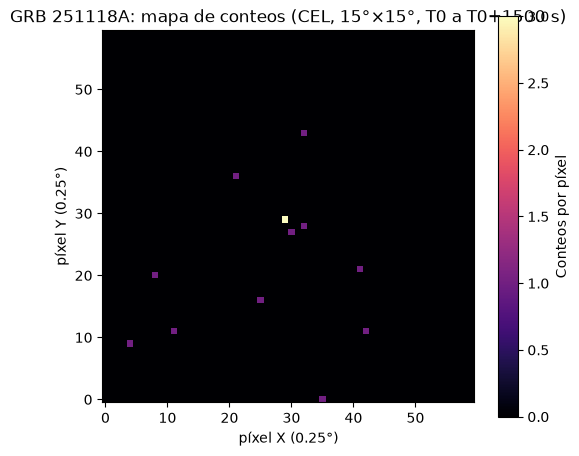

Coordenadas galácticas del GRB: l = 274.3°, b = 21.0°
Con ROI de 15°, el plano galáctico (b=0) queda fuera de la ROI.


In [14]:
mapa = fits.getdata('data/cmap_251118A.fits')
plt.figure(figsize=(6, 5.2))
plt.imshow(mapa, origin='lower', cmap='magma')
plt.colorbar(label='Conteos por píxel')
plt.title('GRB 251118A: mapa de conteos (CEL, 15°×15°, T0 a T0+1500 s)')
plt.xlabel('píxel X (0.25°)'); plt.ylabel('píxel Y (0.25°)')
plt.show()

# ¿Qué tan cerca está el plano galáctico? (para dimensionar la contaminación difusa)
gal = pos_grb.galactic
print(f"Coordenadas galácticas del GRB: l = {gal.l.deg:.1f}°, b = {gal.b.deg:.1f}°")
print(f"Con ROI de {os.environ['ROI']}°, el plano galáctico (b=0) "
      f"{'SÍ queda dentro de la ROI' if abs(gal.b.deg) < float(os.environ['ROI']) else 'queda fuera de la ROI'}.")

> **Fuentes de catálogo en la ROI:** un análisis riguroso incluiría las fuentes del catálogo 4FGL
> dentro de la región (por ejemplo generando el XML con `make4FGLxml`). En un intervalo de 1500 s su contribución es muy
> pequeña comparada con los difusos, pero hay que **declararlo**: aquí el modelo solo lleva el GRB y los
> dos fondos difusos, y esa es una limitación conocida del análisis.

## 7. Modelo de la región de interés y exposición

### 7a. El modelo XML (tres componentes)

1. **GRB_251118A**: fuente puntual en la posición del afterglow de UVOT, espectro `PowerLaw2`
   (N(E) ∝ E^Γ normalizada por su integral entre 100 MeV y 300 GeV). Parámetros libres: `Integral`
   (el flujo) e `Index` (Γ).
2. **Fondo difuso galáctico**: la emisión de la Vía Láctea producida por los rayos cósmicos al
   interactuar con el gas interestelar. Se modela con el mapa estándar `gll_iem_v07.fits`, generado con
   el código **GALPROP** (de ahí que se le llame «GALPROP» en las tablas: es el nombre del código de
   propagación de rayos cósmicos con que se construyó el mapa). Su único parámetro es la normalización
   `Value` (1 = el valor nominal del mapa).
3. **Fondo isotrópico**: el difuso extragaláctico más el residuo de partículas mal clasificadas,
   como ley de potencia de índice fijo −2.1. Con tan pocos fotones, su prefactor se deja **fijo en el
   valor de catálogo** (1.6×10⁻⁷): si se libera, la matriz de covarianza deja de ser definida positiva
   (demasiados parámetros para 30–40 fotones). Esto hay que declararlo al reportar el ajuste.

### La exploración de variantes del modelo

Con tan pocos fotones, la decisión de **qué parámetros se fijan y cuáles se dejan libres** importa más
que ninguna otra, así que se explora de forma sistemática: **cuatro variantes** del mismo modelo sobre
los mismos datos, cada una con sus grados de libertad anotados. Cuando un parámetro se fija, se fija a
un valor con respaldo: el índice, al **−1.8** publicado en la GCN; las normalizaciones de los difusos,
a su valor de catálogo:

| Variante | Índice del GRB | GALPROP | Espectro GRB | Parámetros libres (grados de libertad) |
|---|---|---|---|---|
| **V1** (base) | libre | libre | `PowerLaw2` | Integral, Index, Value (**3**) |
| **V2** | libre | fijo = 1.0 | `PowerLaw2` | Integral, Index (**2**) |
| **V3** | fijo = −1.8 (GCN) | fijo = 1.0 | `PowerLaw2` | solo Integral (**1**) |
| **V4** | libre | libre | `PowerLaw` | Prefactor, Index, Value (**3**) |

Cada comparación aísla **una** decisión de modelado:

- **V1 vs. V2** aísla el efecto de fijar el fondo galáctico. Es la decisión de mayor impacto: con pocos
  fotones, una normalización galáctica libre puede alejarse de 1 (su valor físico nominal) absorbiendo
  señal del GRB y agrandando el error del flujo; fijarla en 1 lo evita.
- **V2 vs. V3** aísla el efecto de fijar además el índice al valor de la GCN. Si el índice libre de V2
  ya converge cerca de −1.8, V3 no debería cambiar casi nada más que quitar un grado de libertad — y
  tener presente que fijar el índice al valor publicado solo es posible porque este GRB
  ya tiene circular; para un evento nuevo no se conocería a priori.
- **V1 vs. V4** aísla la parametrización: `PowerLaw` y `PowerLaw2` son la misma ley de potencia escrita
  distinto (prefactor en una energía de referencia vs. flujo integrado entre dos energías), así que V4
  debe reproducir a V1 casi exactamente. Es una prueba de consistencia, no un modelo nuevo.

**El resultado reportable es V2**: mide el índice con los datos propios (no lo copia de la GCN) y
mantiene el fondo galáctico en su valor físico. V3 sirve para dar el flujo con el índice de la GCN y
comparar peras con peras; V1 y V4 son el contraste que justifica esas decisiones.


In [15]:
import os

def espectro_grb(index_fijo=None, powerlaw_simple=False):
    """Bloque <spectrum> de la fuente puntual del GRB según la variante."""
    idx_free = "false" if index_fijo is not None else "true"
    idx_val = index_fijo if index_fijo is not None else -2.0
    if powerlaw_simple:   # V4: PowerLaw (prefactor en la energía de referencia Scale)
        return f"""<spectrum type="PowerLaw">
      <parameter free="true" max="1000.0" min="1e-05" name="Prefactor" scale="1e-09" value="1.0"/>
      <parameter free="{idx_free}" max="-1.0" min="-5.0" name="Index" scale="1.0" value="{idx_val}"/>
      <parameter free="false" max="2000.0" min="30.0" name="Scale" scale="1.0" value="100.0"/>
    </spectrum>"""
    return f"""<spectrum type="PowerLaw2">
      <parameter free="true" max="1000.0" min="1e-05" name="Integral" scale="1e-06" value="1.0"/>
      <parameter free="{idx_free}" max="-1.0" min="-5.0" name="Index" scale="1.0" value="{idx_val}"/>
      <parameter free="false" max="300000.0" min="20.0" name="LowerLimit" scale="1.0" value="100.0"/>
      <parameter free="false" max="300000.0" min="20.0" name="UpperLimit" scale="1.0" value="300000.0"/>
    </spectrum>"""

def modelo_xml(index_fijo=None, galprop_libre=True, powerlaw_simple=False):
    gal_free = "true" if galprop_libre else "false"
    return f"""<?xml version="1.0" ?>
<source_library title="Source Library" xmlns="http://fermi.gsfc.nasa.gov/source_library">
  <source name="GRB_251118A" type="PointSource">
    {espectro_grb(index_fijo, powerlaw_simple)}
    <spatialModel type="SkyDirFunction">
      <parameter free="false" max="360.0" min="0.0" name="RA" scale="1.0" value="{os.environ['RA_GRB']}"/>
      <parameter free="false" max="90.0" min="-90.0" name="DEC" scale="1.0" value="{os.environ['DEC_GRB']}"/>
    </spatialModel>
  </source>
  <source name="GALPROP Diffuse Source" type="DiffuseSource">
    <spectrum type="ConstantValue">
      <parameter free="{gal_free}" max="10.0" min="0.0" name="Value" scale="1.0" value="1.0"/>
    </spectrum>
    <spatialModel file="$(FERMI_DIR)/refdata/fermi/galdiffuse/gll_iem_v07.fits" type="MapCubeFunction">
      <parameter free="false" max="1000.0" min="0.001" name="Normalization" scale="1.0" value="1.0"/>
    </spatialModel>
  </source>
  <source name="Extragalactic Diffuse Source" type="DiffuseSource">
    <spectrum type="PowerLaw">
      <parameter free="false" max="100.0" min="1e-05" name="Prefactor" scale="1e-07" value="1.6"/>
      <parameter free="false" max="-1.0" min="-3.5" name="Index" scale="1.0" value="-2.1"/>
      <parameter free="false" max="200.0" min="50.0" name="Scale" scale="1.0" value="100.0"/>
    </spectrum>
    <spatialModel type="ConstantValue">
      <parameter free="false" max="10.0" min="0.0" name="Value" scale="1.0" value="1.0"/>
    </spatialModel>
  </source>
</source_library>"""

VARIANTES = {
    'V1': dict(index_fijo=None, galprop_libre=True,  powerlaw_simple=False),  # base: todo libre
    'V2': dict(index_fijo=None, galprop_libre=False, powerlaw_simple=False),  # GALPROP fijo (reportable)
    'V3': dict(index_fijo=-1.8, galprop_libre=False, powerlaw_simple=False),  # + índice GCN fijo
    'V4': dict(index_fijo=None, galprop_libre=True,  powerlaw_simple=True),   # PowerLaw, equivalencia con V1
}
for v, conf in VARIANTES.items():
    with open(f'data/modelo_{v}.xml', 'w') as f:
        f.write(modelo_xml(**conf))
    print(f'Escrito data/modelo_{v}.xml  {conf}')

Escrito data/modelo_V1.xml  {'index_fijo': None, 'galprop_libre': True, 'powerlaw_simple': False}
Escrito data/modelo_V2.xml  {'index_fijo': None, 'galprop_libre': False, 'powerlaw_simple': False}
Escrito data/modelo_V3.xml  {'index_fijo': -1.8, 'galprop_libre': False, 'powerlaw_simple': False}
Escrito data/modelo_V4.xml  {'index_fijo': None, 'galprop_libre': True, 'powerlaw_simple': True}


In [16]:
%%bash
# El mapa galáctico debe estar en el entorno; se baja solo si falta (~500 MB).
destino="$FERMI_DIR/refdata/fermi/galdiffuse/gll_iem_v07.fits"
if [ -f "$destino" ]; then echo "Ya existe: $destino"
else wget -nc https://fermi.gsfc.nasa.gov/ssc/data/analysis/software/aux/gll_iem_v07.fits -P "$FERMI_DIR/refdata/fermi/galdiffuse/"
fi

Ya existe: /home/fabriciooos/miniconda3/envs/fermi/share/fermitools/refdata/fermi/galdiffuse/gll_iem_v07.fits


### 7b. `gtdiffrsp`: contribución difusa por fotón

Para cada fotón calcula la integral del modelo de cada componente difusa (convuelta con la PSF y el
área efectiva) y la guarda en las columnas `DIFRSP0`/`DIFRSP1` del archivo de eventos; sin esto el
ajuste no puede repartir cada fotón entre el GRB y los fondos. Modifica `analisis_mktime.fits` en el
lugar y tarda varios minutos. Las cuatro variantes del modelo tienen las **mismas componentes difusas**
(solo cambia qué parámetros quedan libres), así que basta correrlo una vez, con cualquiera de ellas.


In [17]:
%%bash
gtdiffrsp \
    evfile=data/analisis_mktime.fits \
    scfile=data/FT2.fits \
    srcmdl=data/modelo_V1.xml \
    irfs=P8R3_SOURCE_V3

adding source Extragalactic Diffuse Source
adding source GALPROP Diffuse Source


Working on...
data/analisis_mktime.fits...................................!


### 7c. `gtltcube` y `gtexpmap`: la exposición

- `gtltcube` precalcula el **tiempo efectivo de observación** acumulado por el instrumento, en función
  de la posición en el cielo y del ángulo de incidencia **respecto al boresight del LAT** (es una
  propiedad de cómo apuntó el telescopio, no del GRB).
- `gtexpmap` combina ese cubo con el área efectiva de la IRF para producir el **mapa de exposición**
  (unidades de cm²·s): la integral de área efectiva × tiempo en cada punto y energía de la ROI. Es
  *exposición*, no «sensibilidad» (son cosas distintas): es el factor que convierte flujo esperado
  en conteos esperados en el ajuste unbinned.
- El radio de la *source region* (25°) = ROI (15°) + 10° de colchón para las colas de la PSF de fuentes
  justo fuera de la región (recomendado cuando la energía mínima es 100 MeV).


In [18]:
%%bash
gtltcube \
    evfile=data/analisis_mktime.fits \
    scfile=data/FT2.fits \
    outfile=data/ltcube.fits \
    dcostheta=0.025 binsz=0.5

gtexpmap \
    evfile=data/analisis_mktime.fits \
    scfile=data/FT2.fits \
    expcube=data/ltcube.fits \
    outfile=data/expmap.fits \
    irfs=P8R3_SOURCE_V3 \
    srcrad=25 nlong=100 nlat=100 nenergies=20

Working on file data/FT2.fits
..........................!
The exposure maps generated by this tool are meant
to be used for *unbinned* likelihood analysis only.
Do not use them for binned analyses.
Half-degree pixels are a nominal choice for point-source analysis.When working on extended sources, the pixel size of the exposure map must be small enough to sample the smallest extended source present in the model.


Computing the ExposureMap using data/ltcube.fits


....................!


## 8. Ajuste unbinned con `gtlike`

**Qué es la verosimilitud y qué es el método UNBINNED:** la verosimilitud $\mathcal{L}$ es la
probabilidad de haber observado exactamente estos fotones (cada uno con su energía, posición y tiempo de
llegada) si el modelo fuera cierto; ajustar por máxima verosimilitud es buscar los parámetros del modelo
que hacen esa probabilidad máxima. En el método UNBINNED, en lugar de agrupar los fotones en bins, la
verosimilitud se evalúa fotón por fotón:

$$\ln \mathcal{L} = \sum_{i\,=\,\mathrm{fotones}} \ln M(E_i, \vec{x}_i, t_i) - N_{\mathrm{pred}}$$

donde $M$ es la densidad del modelo (GRB + fondos, multiplicada por la exposición) evaluada en la
energía, posición y tiempo de cada fotón, y $N_{\mathrm{pred}}$ es el total de conteos que el modelo
predice. Con pocas decenas de fotones es el método apropiado: no desperdicia información agrupando.
El optimizador es **MINUIT** (James & Roos 1975, *Comput. Phys. Commun.* 10, 343).

**Qué es el TS (y qué no es):** el *Test Statistic* se define como
$\mathrm{TS} = -2\ln(\mathcal{L}_0/\mathcal{L}_1)$, con $\mathcal{L}_0$ la verosimilitud máxima
**sin** el GRB y $\mathcal{L}_1$ **con** él. El TS **no es la significancia**: para un parámetro libre
extra, la significancia aproximada es $\sqrt{\mathrm{TS}}\,\sigma$ (teorema de Wilks), de donde viene
la regla de que TS ≳ 25 ↔ ~5σ. Dos cautelas con pocos fotones: la aproximación de Wilks es asintótica
(con decenas de fotones es orientativa, no exacta), y al comparar TS entre modelos hay que verificar que
tengan los **mismos grados de libertad** — si no, parte de la diferencia es solo por los parámetros
extra (entre el modelo base y el de GALPROP fijo hay 1 grado de libertad de diferencia).

### 8a. Las cuatro variantes, con el mismo flujo de trabajo

La celda corre `gtlike` una vez por variante (V1 a V4, definidas en la sección 7a); lo único que cambia
entre corridas es el modelo XML. Cada corrida guarda sus resultados (`results_V*.dat`), el modelo
ajustado (`salida_V*.xml`) y su `counts_spectra` con nombre propio (la corrida siguiente lo
sobreescribiría). Son varios minutos por variante.


In [19]:
%%bash
for V in V1 V2 V3 V4; do
  echo "========================== $V =========================="
  gtlike plot=no results=data/results_${V}.dat \
      statistic=UNBINNED \
      scfile=data/FT2.fits \
      evfile=data/analisis_mktime.fits \
      expmap=data/expmap.fits \
      expcube=data/ltcube.fits \
      srcmdl=data/modelo_${V}.xml \
      sfile=data/salida_${V}.xml \
      irfs=P8R3_SOURCE_V3 \
      optimizer=MINUIT
  [ -f counts_spectra.fits ] && mv counts_spectra.fits data/counts_spectra_${V}.fits
done

========================== V1 ==========================
100  1.34746e+06
108.423  1.50789e+06
117.556  1.68361e+06
127.458  1.86729e+06
138.194  2.05944e+06
149.835  2.24839e+06
162.456  2.43944e+06
176.14  2.62104e+06
190.976  2.80064e+06
207.063  2.97206e+06
224.504  3.1397e+06
243.415  3.2889e+06
263.918  3.43534e+06
286.149  3.58235e+06
310.252  3.73267e+06
336.385  3.88484e+06
364.72  4.02449e+06
395.441  4.16165e+06
428.75  4.29044e+06
464.864  4.41544e+06
504.021  4.53462e+06
546.476  4.65774e+06
592.507  4.78427e+06
642.416  4.90881e+06
696.528  5.03277e+06
755.198  5.12337e+06
818.81  5.21824e+06
887.781  5.33507e+06
962.561  5.46817e+06
1043.64  5.62391e+06
1131.55  5.73469e+06
1226.86  5.82002e+06
1330.2  5.91628e+06
1442.25  6.01259e+06
1563.73  6.09106e+06
1695.45  6.16096e+06
1838.26  6.21082e+06
1993.1  6.24119e+06
2160.99  6.2536e+06
2343.01  6.2475e+06
2540.37  6.23494e+06
2754.35  6.20971e+06
2986.36  6.18506e+06
3237.91  6.16487e+06
3510.65  6.14562e+06
3806.36  6.1

...!


Flux: 0.000656641 +/- 0.000175728 photons/cm^2/s

GRB_251118A:
Integral: 2.07918 +/- 1.01613
Index: -1.76939 +/- 0.300417
LowerLimit: 100
UpperLimit: 300000
Npred: 7.38128
ROI distance: 0
TS value: 42.6632
Flux: 2.07985e-06 +/- 1.01614e-06 photons/cm^2/s


Total number of observed counts: 35
Total number of model events: 37.0045

-log(Likelihood): 356.1144907

Writing fitted model to data/salida_V1.xml
Elapsed CPU time: 58.880668
========================== V2 ==========================
100  1.34746e+06
108.423  1.50789e+06
117.556  1.68361e+06
127.458  1.86729e+06
138.194  2.05944e+06
149.835  2.24839e+06
162.456  2.43944e+06
176.14  2.62104e+06
190.976  2.80064e+06
207.063  2.97206e+06
224.504  3.1397e+06
243.415  3.2889e+06
263.918  3.43534e+06
286.149  3.58235e+06
310.252  3.73267e+06
336.385  3.88484e+06
364.72  4.02449e+06
395.441  4.16165e+06
428.75  4.29044e+06
464.864  4.41544e+06
504.021  4.53462e+06
546.476  4.65774e+06
592.507  4.78427e+06
642.416  4.90881e+06
696.528  5.032

...!


Flux: 0.000520928 photons/cm^2/s

GRB_251118A:
Integral: 2.21484 +/- 1.03405
Index: -1.7982 +/- 0.296144
LowerLimit: 100
UpperLimit: 300000
Npred: 7.75347
ROI distance: 0
TS value: 46.0417
Flux: 2.2156e-06 +/- 1.03405e-06 photons/cm^2/s


Total number of observed counts: 35
Total number of model events: 33.192

-log(Likelihood): 356.4466344

Writing fitted model to data/salida_V2.xml
Elapsed CPU time: 56.840633
========================== V3 ==========================
100  1.34746e+06
108.423  1.50789e+06
117.556  1.68361e+06
127.458  1.86729e+06
138.194  2.05944e+06
149.835  2.24839e+06
162.456  2.43944e+06
176.14  2.62104e+06
190.976  2.80064e+06
207.063  2.97206e+06
224.504  3.1397e+06
243.415  3.2889e+06
263.918  3.43534e+06
286.149  3.58235e+06
310.252  3.73267e+06
336.385  3.88484e+06
364.72  4.02449e+06
395.441  4.16165e+06
428.75  4.29044e+06
464.864  4.41544e+06
504.021  4.53462e+06
546.476  4.65774e+06
592.507  4.78427e+06
642.416  4.90881e+06
696.528  5.03277e+06
755.198  5.1

...!


Flux: 0.000520928 photons/cm^2/s

GRB_251118A:
Integral: 2.21784 +/- 0.901579
Index: -1.8
LowerLimit: 100
UpperLimit: 300000
Npred: 7.75724
ROI distance: 0
TS value: 46.0416
Flux: 2.21861e-06 +/- 9.01582e-07 photons/cm^2/s


Total number of observed counts: 35
Total number of model events: 33.1958

-log(Likelihood): 356.4466534

Writing fitted model to data/salida_V3.xml
Elapsed CPU time: 55.050289
========================== V4 ==========================
100  1.34746e+06
108.423  1.50789e+06
117.556  1.68361e+06
127.458  1.86729e+06
138.194  2.05944e+06
149.835  2.24839e+06
162.456  2.43944e+06
176.14  2.62104e+06
190.976  2.80064e+06
207.063  2.97206e+06
224.504  3.1397e+06
243.415  3.2889e+06
263.918  3.43534e+06
286.149  3.58235e+06
310.252  3.73267e+06
336.385  3.88484e+06
364.72  4.02449e+06
395.441  4.16165e+06
428.75  4.29044e+06
464.864  4.41544e+06
504.021  4.53462e+06
546.476  4.65774e+06
592.507  4.78427e+06
642.416  4.90881e+06
696.528  5.03277e+06
755.198  5.12337e+06
818.

...!


Flux: 0.000656297 +/- 0.000175671 photons/cm^2/s

GRB_251118A:
Prefactor: 15.999 +/- 12.1616
Index: -1.76923 +/- 0.300157
Scale: 100
Npred: 7.36875
ROI distance: 0
TS value: 42.6632
Flux: 2.07615e-06 +/- 2.28636e-06 photons/cm^2/s


Total number of observed counts: 35
Total number of model events: 36.9814

-log(Likelihood): 356.1144978

Writing fitted model to data/salida_V4.xml
Elapsed CPU time: 56.329626


### 8b. Resumen comparado de las cuatro variantes

La celda siguiente junta lo que debe reportarse **siempre**: TS con su significancia
aproximada (√TS) y, sobre todo, **los grados de libertad de cada variante al lado de su TS** — sin eso
las variantes no se pueden comparar entre sí. Después imprime el detalle completo de cada ajuste, para
leer índice, flujo, Npred y las normalizaciones de los difusos.


In [25]:
import re, math

DOF = {'V1': 3, 'V2': 2, 'V3': 1, 'V4': 3}
DESCR = {'V1': 'base: índice y GALPROP libres',
         'V2': 'GALPROP fijo en 1 (reportable)',
         'V3': 'índice fijo en -1.8 (GCN) y GALPROP fijo en 1',
         'V4': 'PowerLaw en vez de PowerLaw2 (equivalencia con V1)'}

textos = {}
print(f"{'Variante':<9} {'g.l.':>4} {'TS':>8} {'≈σ (√TS)':>9}   descripción")
for V in ['V1', 'V2', 'V3', 'V4']:
    try:
        textos[V] = open(f'data/results_{V}.dat').read()
    except FileNotFoundError:
        print(f"{V:<9}  (aún no se corre)"); continue
    m = re.search(r"TS value\'?\s*:\s*\'?([0-9.eE+-]+)", textos[V])
    ts = float(m.group(1)) if m else float('nan')
    print(f"{V:<9} {DOF[V]:>4} {ts:>8.2f} {math.sqrt(ts):>8.1f}σ   {DESCR[V]}")

print("""
Cómo leerlo:
- V1 vs V2 aísla el fondo galáctico: si al fijarlo el TS sube y el error del flujo baja, GALPROP libre
  estaba absorbiendo señal (revisar su Value en V1: ~1.5 es la señal de alarma).
- V2 vs V3 aísla fijar el índice al -1.8 de la GCN: con un grado de libertad menos, el TS puede subir
  un poco sin que eso signifique mejor física (es pura cuenta de parámetros).
- V4 debe calcar a V1 (misma ley de potencia, otra parametrización); si difieren, algo anda mal.
- Reportable: V2. Y siempre contrastar Npred del GRB con el fondo esperado de la sección 4.
""")

for V, txt in textos.items():
    print(f"================ results_{V}.dat ({DESCR[V]}) ================")
    print(txt)

Variante  g.l.       TS  ≈σ (√TS)   descripción
V1           3    42.66      6.5σ   base: índice y GALPROP libres
V2           2    46.04      6.8σ   GALPROP fijo en 1 (reportable)
V3           1    46.04      6.8σ   índice fijo en -1.8 (GCN) y GALPROP fijo en 1
V4           3    42.66      6.5σ   PowerLaw en vez de PowerLaw2 (equivalencia con V1)

Cómo leerlo:
- V1 vs V2 aísla el fondo galáctico: si al fijarlo el TS sube y el error del flujo baja, GALPROP libre
  estaba absorbiendo señal (revisar su Value en V1: ~1.5 es la señal de alarma).
- V2 vs V3 aísla fijar el índice al -1.8 de la GCN: con un grado de libertad menos, el TS puede subir
  un poco sin que eso signifique mejor física (es pura cuenta de parámetros).
- V4 debe calcar a V1 (misma ley de potencia, otra parametrización); si difieren, algo anda mal.
- Reportable: V2. Y siempre contrastar Npred del GRB con el fondo esperado de la sección 4.

================ results_V1.dat (base: índice y GALPROP libres) ================
{

### 8c. Espectro de conteos y componentes del modelo (Python)

La gráfica interactiva de `gtlike` (`plot=yes`) ya no está disponible en las versiones recientes de
Fermitools; en su lugar, `gtlike` deja `counts_spectra.fits` con los conteos observados y los de cada
componente del modelo por bin de energía, y el espectro se grafica con Python: **negro = suma del modelo, rojo = GRB, verde = difuso galáctico (GALPROP),
azul = difuso extragaláctico**, los datos con barras de error poissonianas y un panel de residuos
(conteos − modelo)/modelo. Se grafica la variante reportable (V2); para ver otra, cambiar `cual` en la
primera línea.


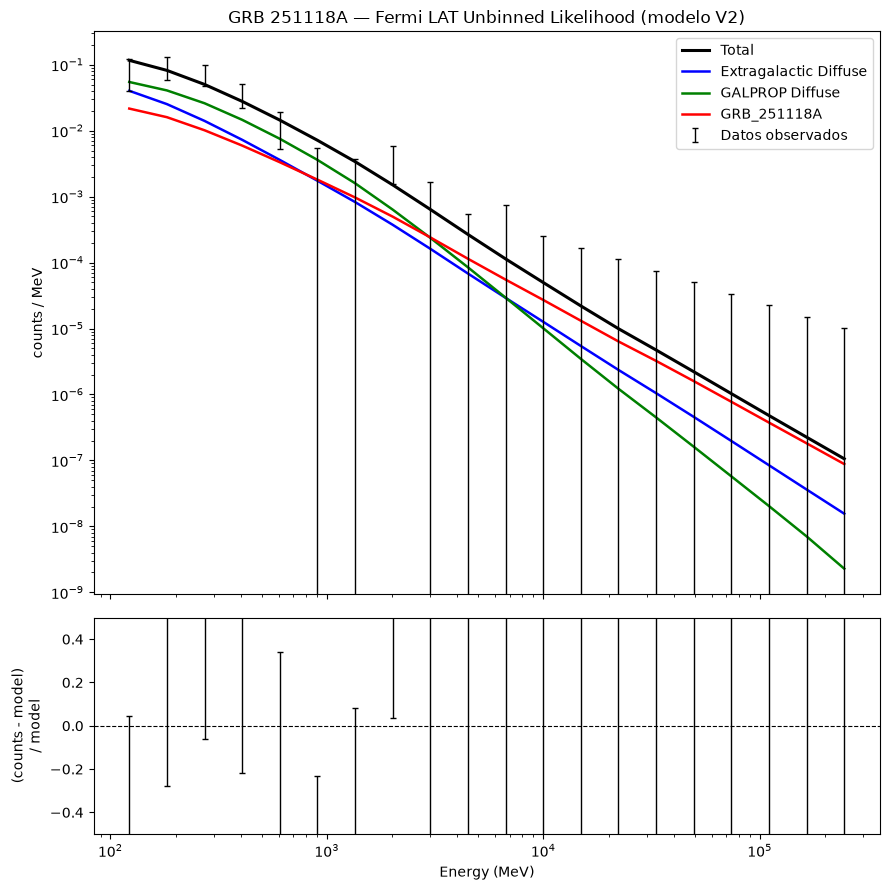

Conteos observados: 35.0 | predichos: 33.21
  Extragalactic Diffuse Source: Npred = 9.38
  GALPROP Diffuse Source: Npred = 16.08
  GRB_251118A: Npred = 7.75


In [21]:
cual = 'V2'        # 'V1', 'V2' (reportable), 'V3' o 'V4'
ruta = f'data/counts_spectra_{cual}.fits'

with fits.open(ruta) as f:
    esp = f['COUNTS_SPECTRA'].data
    eb = f['EBOUNDS'].data

E = np.sqrt(eb['E_MIN'] * eb['E_MAX'])          # centro geométrico del bin (MeV)
dE = eb['E_MAX'] - eb['E_MIN']                  # ancho del bin (MeV)
obs = esp['ObsCounts'].astype(float)
componentes = [n for n in esp.columns.names if n != 'ObsCounts']
total = np.sum([esp[n] for n in componentes], axis=0)
colores = {n: ('red' if 'GRB' in n else 'green' if 'GALPROP' in n.upper() else 'blue')
           for n in componentes}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 9), sharex=True,
                               gridspec_kw={'height_ratios': [2.6, 1]})
ax1.plot(E, total/dE, 'k-', lw=2.2, label='Total')
for n in componentes:
    ax1.plot(E, esp[n]/dE, color=colores[n], lw=1.8, label=n.replace(' Source', ''))
yerr = np.sqrt(np.maximum(obs, 1.0))
ax1.errorbar(E, obs/dE, yerr=yerr/dE, fmt='none', ecolor='k', elinewidth=1,
             capsize=2, label='Datos observados')
ax1.set_xscale('log'); ax1.set_yscale('log')
ax1.set_ylabel('counts / MeV')
ax1.set_title(f'GRB 251118A — Fermi LAT Unbinned Likelihood (modelo {cual})')
ax1.legend()

con = total > 0
ax2.errorbar(E[con], (obs[con]-total[con])/total[con], yerr=yerr[con]/total[con],
             fmt='none', ecolor='k', elinewidth=1, capsize=2)
ax2.axhline(0, color='k', ls='--', lw=0.8)
ax2.set_xscale('log')
ax2.set_ylim(-0.5, 0.5)
ax2.set_xlabel('Energy (MeV)')
ax2.set_ylabel('(counts - model)\n/ model')
plt.tight_layout()
plt.savefig(f'data/Espectro_251118A_{cual}.png', dpi=150)
plt.show()

print('Conteos observados:', obs.sum(), '| predichos: %.2f' % total.sum())
for n in componentes:
    print(f'  {n}: Npred = {esp[n].sum():.2f}')

## 9. Análisis binned (XSPEC)

Como verificación independiente del índice espectral se hace también el ajuste *binned*: el espectro se
agrupa en canales y se ajusta en XSPEC. Para un espectro integrado en el tiempo con pocos conteos no es
el método principal (ese es el unbinned), pero sirve de control cruzado — y al final se comparan ambos.

### 9a. `gtbin PHA1`: el espectro de conteos

`PHA1` produce **un solo espectro acumulado** sobre toda la ventana del archivo de entrada, en formato
PHA estándar. Los **canales de salida** son los bins de energía *reconstruida* en los que se cuentan los
fotones: aquí 30 canales logarítmicos entre 100 MeV y 300 GeV.


In [22]:
%%bash
gtbin algorithm=PHA1 \
    evfile=data/analisis_mktime.fits \
    outfile=data/GRB251118A.pha \
    scfile=data/FT2.fits \
    ebinalg=LOG emin=$EMIN emax=$EMAX enumbins=30

This is gtbin version HEAD


### 9b. `gtrspgen`: la matriz de respuesta

Construye, a partir de las IRF (vía `CALDB`, que apunta a `P8R3_SOURCE_V3` para esta clase), la matriz
que conecta los bins de energía del fotón **incidente** (la energía verdadera, antes del detector) con
los **canales de salida** del PHA (la energía reconstruida). Los bins incidentes (100) **sobremuestrean**
los canales de salida (30): como la resolución en energía es finita, calcular la respuesta en una malla
incidente más fina da un número esperado de fotones por canal más preciso.

Se usa el método `PS` (*Point Source*, el recomendado) con `thetacut=90` y `dcostheta=0.5`.


In [23]:
%%bash
gtrspgen respalg=PS \
    specfile=data/GRB251118A.pha \
    scfile=data/FT2.fits \
    outfile=data/GRB251118A.rsp \
    thetacut=90 dcostheta=0.5 \
    irfs=CALDB \
    ebinalg=LOG emin=$EMIN emax=$EMAX enumbins=100

This is gtrspgen version HEAD


### 9c. Ajuste en XSPEC

Modelo `pow` (ley de potencia simple; en XSPEC el índice `PhoIndex` se define positivo:
N(E) ∝ E^(−PhoIndex), así que PhoIndex ≈ 1.8 equivale a Γ = −1.8 de `gtlike`). Estadístico **C-stat**
(pocos conteos). Tres detalles importan aquí:

- Los residuos se grafican **normalizados por la incertidumbre de cada punto** (`plot ldata delchi`,
  que muestra (dato − modelo)/error), no los residuos crudos.
- La «probabilidad nula» que imprime XSPEC proviene de la estadística χ² y **no es interpretable cuando
  se ajusta con C-stat y pocos conteos** (puede imprimir valores absurdos, como un 1.00 exacto, que no
  significan nada). La bondad del
  ajuste se evalúa con C-stat frente a los grados de libertad (canales con datos menos parámetros
  libres, aquí 2) o simulando con el comando `goodness`.
- Con ~30–40 fotones repartidos en 30 canales logarítmicos, la mayoría de los canales queda con 0, 1 o
  2 conteos: C-stat está hecho justamente para ese régimen, pero cualquier intuición de χ² sobra aquí.
  Si se quieren canales más poblados, bajar `enumbins` a 15 en `gtbin PHA1` **y** regenerar la RSP con
  los mismos bordes; los resultados del índice no deberían moverse de forma apreciable.

**Una honestidad necesaria:** este ajuste **no tiene modelo de fondo** — XSPEC ajusta una sola ley de
potencia a los 35 fotones de la región, de los cuales ~25 son difusos. El PhoIndex que salga es, por
tanto, el índice del **total** (GRB + fondos), no el del GRB aislado; por eso aquí el binned es un
control de forma espectral y de orden de magnitud, y la medición del GRB puro es la del unbinned, que sí
separa las componentes. (En el caso del tutorial, GRB 080916C, el binned sí mide al GRB: ahí el fondo es
despreciable.)

Si corres sin entorno gráfico, cambia `cpd /xs` por `cpd /null`.

**Detalle práctico:** `gtrspgen` graba en el PHA
`RESPFILE = 'data/GRB251118A.rsp'` con la ruta relativa al cuaderno; si XSPEC se abre desde otra
carpeta, no la encuentra y entra al modo «New filename», que espera solo nombres de archivo. La celda
siguiente reescribe `RESPFILE` con el nombre a secas y declara `POISSERR = T` (conteos poissonianos, lo
que además quita un *warning*); después XSPEC se corre desde `data/` y carga la respuesta solo. Si aun
así preguntara `New filename`, respóndele únicamente con el nombre del archivo (sin `response`).


In [24]:
# Arreglo del encabezado del PHA antes de XSPEC (correr después de gtrspgen):
from astropy.io import fits as _fits
_fits.setval('data/GRB251118A.pha', 'RESPFILE', value='GRB251118A.rsp', ext=1)
_fits.setval('data/GRB251118A.pha', 'POISSERR', value=True, ext=1)
print('RESPFILE ->', _fits.getval('data/GRB251118A.pha', 'RESPFILE', ext=1))
print('POISSERR ->', _fits.getval('data/GRB251118A.pha', 'POISSERR', ext=1))

RESPFILE -> GRB251118A.rsp
POISSERR -> True


In [ ]:
%%bash
cd data
xspec <<'EOF'
query yes
data GRB251118A.pha
model pow
1.8
1.0
statistic cstat
cpd /xs
setplot energy
fit
plot ldata delchi
goodness 1000
# (si goodness da error en esta version de XSPEC, puede omitirse:
#  la bondad se evalua con C-stat frente a los grados de libertad)
show all
exit
EOF

El resultado del ajuste con xspec es el siguiente: 
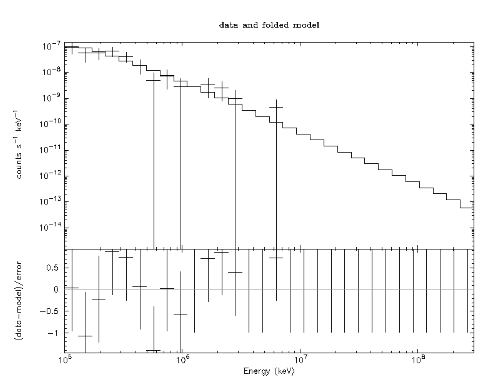

Y el flujo fue el siguiente: 


                XSPEC version: 13.0.1
        Build Date/Time: Sun Oct  4 19:23:18 2026

XSPEC>data GRB251118.pha
Error: cannot read spectrum file GRB251118.pha
New filename ( "none" or "/*" to return to the XSPEC prompt): GRB251118A.pha
***Warning: Data file GRB251118A.pha has both POISSERR key set to 'true' and a STAT_ERR column.
   XSPEC will assume Poisson errors.

1 spectrum  in use
 
Spectral Data File: GRB251118A.pha  Spectrum 1
Net count rate (cts/s) for Spectrum:1  2.612e-02 +/- 4.415e-03
 Assigned to Data Group 1 and Plot Group 1
  Noticed Channels:  1-30
  Telescope: GLAST Instrument: LAT  Channel Type: PI
  Exposure Time: 1340 sec
 Using fit statistic: chi
 Using Response (RMF) File            GRB251118A.rsp for Source 1

XSPEC>model pow

Input parameter value, delta, min, bot, top, and max values for ...
              1       0.01(      0.01)         -3         -2          9         10
1:powerlaw:PhoIndex>1.85
              1       0.01(      0.01)          0          0      1e+20      1e+24
2:powerlaw:norm>

Fit statistic  : Chi-Squared                  858.50     using 30 bins.

***Warning: Chi-square may not be valid due to bins with zero variance
            in spectrum number: 1

Test statistic : Chi-Squared                  858.50     using 30 bins.

***Warning: Chi-square may not be valid due to bins with zero variance
            in spectrum number(s): 1 

 Null hypothesis probability of 1.06e-162 with 28 degrees of freedom
 Current data and model not fit yet.

========================================================================
Model powerlaw<1> Source No.: 1   Active/On
Model Model Component  Parameter  Unit     Value
 par  comp
   1    1   powerlaw   PhoIndex            1.85000      +/-  0.0          
   2    1   powerlaw   norm                1.00000      +/-  0.0          
________________________________________________________________________

XSPEC>statistic cstat
Default fit statistic is set to: C-Statistic
   This will apply to all current and newly loaded spectra.

Fit statistic  : C-Statistic                  221.06     using 30 bins.

Test statistic : Chi-Squared                  858.50     using 30 bins.

***Warning: Chi-square may not be valid due to bins with zero variance
            in spectrum number(s): 1 

 Null hypothesis probability of 1.06e-162 with 28 degrees of freedom
 Current data and model not fit yet.
XSPEC>cpd /xs
XSPEC>setplot energy
XSPEC>fit
                                   Parameters
C-Statistic  |beta|/N    Lvl    1:PhoIndex        2:norm
LM is using analytic gradients (better numerical accuracy on tabulated models).
Parameter uncertainties may differ from previous FD-based fits; on expensive-likelihood fits (large
response convolutions) per-iteration cost may be higher.  Set "xset DISABLE_ANALYTIC_GRAD yes" to
revert to finite differences.
14.1         3.47997      -2       1.85603      0.188037
14.0311      1.32519      -2       1.86135      0.201583
13.9677      1.17869      -2       1.86641      0.215533
13.9095      1.09389      -2       1.87127      0.229813
13.896       1.02609      -3       1.90916      0.343363
13.5338      20.9234      -3       1.92956      0.466169
13.363       12.5465      -3       1.94589      0.591517
13.2845      7.15036      -3       1.95855      0.708307
13.2482      3.86221      -3       1.96814      0.809437
13.2311      1.99543      -3       1.97528      0.892329
Number of trials exceeded: continue fitting? 
13.2227      0.993816     -3       1.98053      0.957661
==============================
 Variances and Principal Axes
                 1        2  
 1.6901E-04|  0.9963  -0.0859  
 3.8918E+00|  0.0859   0.9963  
------------------------------

========================
  Covariance Matrix
        1           2   
   2.891e-02   3.332e-01
   3.332e-01   3.863e+00
------------------------

========================================================================
Model powerlaw<1> Source No.: 1   Active/On
Model Model Component  Parameter  Unit     Value
 par  comp
   1    1   powerlaw   PhoIndex            1.98053      +/-  0.170036     
   2    1   powerlaw   norm                0.957661     +/-  1.96547      
________________________________________________________________________


Fit statistic  : C-Statistic                   13.22     using 30 bins.

Test statistic : Chi-Squared                    8.74     using 30 bins.

***Warning: Chi-square may not be valid due to bins with zero variance
            in spectrum number(s): 1 

 Null hypothesis probability of 1.00e+00 with 28 degrees of freedom
XSPEC>plot ldata delchi
XSPEC>goodness 1000
Parameter distribution is derived from fit covariance matrix.

***XSPEC Error:  No variable parameters for fit 
***XSPEC Error: Unable to perform simulations
.
XSPEC>show all

XSPEC version: 13.0.1

Thu Nov 12 08:38:08 2026
 Auto-saving is done after every command.
 Fit statistic in use: C-Statistic
 Minimization technique: Levenberg-Marquardt
    Convergence criterion = 0.01
    Parameter fit deltas: 0.01 * parValue
Using chain rule to calculate statistic derivatives (faster method).
 Querying enabled.
 Prefit-renorming enabled.
 Solar abundance table: angr
 Photoionization Cross-Section Table:
    vern:  Verner, Ferland, Korista, and Yakovlev 1996
 Cosmology in use: H0 = 70 q0 = 0 Lambda0 = 0.73
 Model data directory: /home/fabriciooos/heasoft/x86_64-pc-linux-gnu-libc2.42/../spectral/manager/../modelData/
 Plot settings:
   Showing of individual additive components is OFF.
   Showing of background spectra is OFF.
   Effective area normalization is OFF.
   Current unit settings:
      Energy     = keV
      Wavelength = angstrom, with Y-Axis displayed per Hz
   X-Axis data display mode: Energy
   Spectra plots will be shifted to source frame by redshift value z: 0
   Device: /xs
   Plotting of line IDs is OFF.
   Splashpage is ON.
   xlog for data plots is ON.
   ylog for data plots is OFF.

   Default plot rebin settings for all plot groups:
   Min. Signif.   Max. # Bins   Error Type
        0.00000             1         quad

 Responses read: 
   GRB251118A.rsp associated with spectrum 1 source 1
      energies: 100 channels: 30
 Distinct RMF files: 
     /home/fabriciooos/Descargas/informe-final-correcciones/GRB251118A/data/GRB251118A.rsp

1 file 1 spectrum 
Spectrum 1  Spectral Data File: GRB251118A.pha
Net count rate (cts/s) for Spectrum:1  2.612e-02 +/- 4.415e-03
 Assigned to Data Group 1 and Plot Group 1
  Noticed Channels:  1-30
  Telescope: GLAST Instrument: LAT  Channel Type: PI
  Exposure Time: 1340 sec
 Using fit statistic: cstat
 Using Response (RMF) File            GRB251118A.rsp for Source 1

 Spectral data counts: 35
 Model predicted rate: 2.57886E-02


Current model list:

========================================================================
Model powerlaw<1> Source No.: 1   Active/On
Model Model Component  Parameter  Unit     Value
 par  comp
   1    1   powerlaw   PhoIndex            1.99339      +/-  0.170030     
   2    1   powerlaw   norm                1.12047      +/-  2.11647      
________________________________________________________________________

   Using energies from responses.

Fit statistic  : C-Statistic                   13.22     using 30 bins.

Test statistic : Chi-Squared                    8.64     using 30 bins.

***Warning: Chi-square may not be valid due to bins with zero variance
            in spectrum number(s): 1 

 Null hypothesis probability of 1.00e+00 with 28 degrees of freedom

Bayes is off

XSPEC>exit
 XSPEC: quit


## 10. Comparación binned vs. unbinned vs. GCN

Para cerrar, los resultados de las secciones 8 y 9 se comparan entre sí y con la circular. La celda
siguiente calcula la diferencia de cada par de valores **en unidades de σ combinada**
(|x₁−x₂|/√(σ₁²+σ₂²)), que es la forma correcta de decir «consistente» o «no consistente» en lugar de
compararlos a ojo.


In [26]:
import math

# Resultados de esta corrida (ventana T0 a T0+1500 s, ROI 15°,
# posición UVOT). gtlike: de data/results_V*.dat; XSPEC: PhoIndex 1.98 +/- 0.17 (Gamma = -PhoIndex),
# C-stat = 13.22 con 28 g.l.; el flujo no se midió en XSPEC (la norma queda en sus unidades propias).
res = {
    'gtlike V1 (libres)  ': {'Gamma': -1.769, 'dGamma': 0.300, 'F': 2.080e-6, 'dF': 1.016e-6, 'TS': 42.66},
    'gtlike V2 (GAL=1)   ': {'Gamma': -1.798, 'dGamma': 0.296, 'F': 2.216e-6, 'dF': 1.034e-6, 'TS': 46.04},
    'gtlike V3 (idx fijo)': {'Gamma': -1.800, 'dGamma': 0.0,   'F': 2.219e-6, 'dF': 0.902e-6, 'TS': 46.04},
    'gtlike V4 (PowerLaw)': {'Gamma': -1.769, 'dGamma': 0.300, 'F': 2.076e-6, 'dF': 2.286e-6, 'TS': 42.66},
    'XSPEC (binned)      ': {'Gamma': -1.98,  'dGamma': 0.17,  'F': None,     'dF': None,     'TS': None},
}
GCN = {'Gamma': -1.8, 'dGamma': 0.3, 'F': 1.8e-6, 'dF': 0.7e-6}   # GCN 42752

def sigmas(x1, d1, x2, d2):
    return abs(x1 - x2) / math.sqrt(d1**2 + d2**2)

print(f"{'Análisis':<21} {'Γ':>14} {'vs GCN':>7} | {'Flujo [ph/cm²/s]':>22} {'vs GCN':>7} | {'TS':>6}")
for nombre, r in res.items():
    sG = sigmas(r['Gamma'], r['dGamma'], GCN['Gamma'], GCN['dGamma'])
    if r['F'] is not None:
        sF = sigmas(r['F'], r['dF'], GCN['F'], GCN['dF'])
        flujo = f"{r['F']:>10.2e}±{r['dF']:<9.1e} {sF:>6.1f}σ"
    else:
        flujo = f"{'(norma en unidades XSPEC)':>30}"
    ts = f"{r['TS']:.1f}" if r['TS'] else '---'
    print(f"{nombre:<21} {r['Gamma']:>7.2f}±{r['dGamma']:<5.2f} {sG:>6.1f}σ | {flujo} | {ts:>6}")
print(f"{'GCN 42752':<21} {GCN['Gamma']:>7.2f}±{GCN['dGamma']:<5.2f} {'—':>7} | "
      f"{GCN['F']:>10.2e}±{GCN['dF']:<9.1e} {'—':>7} | {'---':>6}")

print()
print(f"XSPEC vs gtlike V2 (índice): {sigmas(-1.98, 0.17, -1.798, 0.296):.1f}σ")
print(f"Γ del LAT (V2) vs β de Band del GBM (−2.56±0.06): {sigmas(-1.798, 0.296, -2.56, 0.06):.1f}σ")


Análisis                           Γ  vs GCN |       Flujo [ph/cm²/s]  vs GCN |     TS
gtlike V1 (libres)      -1.77±0.30     0.1σ |   2.08e-06±1.0e-06      0.2σ |   42.7
gtlike V2 (GAL=1)       -1.80±0.30     0.0σ |   2.22e-06±1.0e-06      0.3σ |   46.0
gtlike V3 (idx fijo)    -1.80±0.00     0.0σ |   2.22e-06±9.0e-07      0.4σ |   46.0
gtlike V4 (PowerLaw)    -1.77±0.30     0.1σ |   2.08e-06±2.3e-06      0.1σ |   42.7
XSPEC (binned)          -1.98±0.17     0.5σ |      (norma en unidades XSPEC) |    ---
GCN 42752               -1.80±0.30        — |   1.80e-06±7.0e-07         — |    ---

XSPEC vs gtlike V2 (índice): 0.5σ
Γ del LAT (V2) vs β de Band del GBM (−2.56±0.06): 2.5σ


**Cómo leer la comparación (y qué concluir):**

- **Índice:** si Γ de gtlike, el −PhoIndex de XSPEC y el de la GCN coinciden dentro de ~1σ, el espectro
  está bien medido por los dos caminos, que es la verificación cruzada que se buscaba.
- **Flujo:** si el valor central queda por encima del de la GCN, con σ
  combinada se ve si la diferencia es real. Un flujo sistemáticamente alto con esta configuración
  apunta a **fondo dentro de la señal del GRB** (fotones de la ROI atribuidos a la fuente); el fondo
  esperado de la sección 4 y la normalización galáctica del modelo base ayudan a diagnosticarlo.
- **TS:** reportar siempre junto con los grados de libertad del modelo. La significancia aproximada es
  √TS, no el TS mismo.
- Y una cautela general: la GCN es un análisis automático hecho por la colaboración con su
  propia cadena calibrada; que nuestros valores se le parezcan es validación del flujo de trabajo,
  no superioridad del análisis manual.

**Contexto multi-instrumento para la discusión física:**

- El índice del LAT (≈ −1.8) es **más duro** que la β de Band del prompt del GBM (−2.56 ± 0.06): si la
  diferencia sobrevive a las incertidumbres de tu ajuste, la emisión GeV no es la simple extrapolación
  del espectro prompt — consistente con que llega cuando el prompt ya terminó (T90 = 46.6 s).
- Swift-XRT midió el afterglow decayendo como t^(−1.08) desde ~31 ks: la emisión GeV de 400–1500 s y el
  afterglow en X encajan en la misma narrativa de emisión posterior al prompt.
- No hay corrimiento al rojo reportado, así que no se puede calcular la energía isotrópica; dejarlo
  dicho explícitamente también es parte de un análisis completo.

## Resumen de archivos generados

| Archivo | Herramienta | Contenido |
|---|---|---|
| `data/FT1.fits`, `data/FT2.fits` | descarga | eventos y nave, crudos |
| `data/lc_select.fits`, `data/lc_mktime.fits` | `gtselect`, `gtmktime` | ventana larga (curva de luz) |
| `data/analisis_select.fits`, `data/analisis_mktime.fits` | `gtselect`, `gtmktime` (+`gtdiffrsp`) | ventana de análisis T0–T0+1500 |
| `data/lc_251118A.fits`, `data/LC_251118A_larga.png` | `gtbin LC` + Python | curva de luz (dos paneles) |
| `data/PSF_vs_dr_251118A.png` | Python | compatibilidad PSF vs. Δr por fotón |
| `data/cmap_251118A.fits` | `gtbin CMAP` | mapa de conteos (CEL) |
| `data/modelo_V1.xml` … `data/modelo_V4.xml` | Python | las cuatro variantes del modelo de la ROI |
| `data/ltcube.fits`, `data/expmap.fits` | `gtltcube`, `gtexpmap` | exposición |
| `data/results_V1.dat` … `data/results_V4.dat` | `gtlike` | los cuatro ajustes unbinned (+ XML ajustado `salida_V*.xml` y `counts_spectra_V*.fits`) |
| `data/GRB251118A.pha`, `.rsp` | `gtbin PHA1`, `gtrspgen` | espectro y respuesta para XSPEC |

### Posibles extensiones

Tres pruebas naturales para una siguiente iteración: incluir las fuentes del catálogo 4FGL de la ROI
en el modelo (con `make4FGLxml`), repetir el ajuste con una ROI mayor de 15° (la consulta de 30° ya lo
permite) y rehacer el ajuste binned con menos canales (por ejemplo 15) como prueba de estabilidad del
índice.


## Lectura final

**Detección y espectro.** Con la ventana de la GCN ($T_0$ a $T_0+1500$ s), ROI de 15° y la posición del
afterglow de UVOT, la variante reportable (V2: GALPROP fijo en 1) da **TS = 46.0** (significancia
≈ √TS ≈ 6.8σ, con 2 parámetros libres), **Γ = −1.798 ± 0.296** y **flujo
(2.22 ± 1.03)×10⁻⁶ ph cm⁻² s⁻¹**, con Npred(GRB) = 7.8 fotones. Contra la GCN 42752, el índice difiere
0.0σ y el flujo 0.3σ: **consistentes**, con la cuenta hecha y no a ojo (el valor central del flujo
ligeramente mayor es compatible con la fluctuación de Poisson esperable para ~8 fotones atribuidos a la
fuente). El control binned (XSPEC, que ajusta el **total** de la región
sin modelo de fondo) da PhoIndex = 1.98 ± 0.17 (C-stat 13.2 / 28 g.l.), a 0.5σ del unbinned y de la
GCN: la forma espectral del total es coherente con la del GRB más unos difusos de pendiente parecida,
que es lo máximo que ese control puede afirmar; la medición limpia del GRB es la del unbinned.

**La aritmética del fondo.** De los 35 fotones de la ROI, el modelo atribuye 16.1 al difuso galáctico,
9.4 al isotrópico y 7.8 al GRB (total predicho 33.2): **tres de cada cuatro fotones son fondo**. La
estimación empírica con la cola de la ventana larga quedó corta (solo 412 s de GTI después de
$T_0+2000$, con 0 fotones — consistente, pero sin estadística), así que la cifra citable de fondo es la
del modelo. El plano galáctico queda **fuera** de la ROI (b = 21.0°), de modo que la contaminación
galáctica entra por la emisión difusa a latitud media, no por el plano.

**Qué enseñó la exploración de variantes.** Fijar GALPROP (V1→V2) subió el TS de 42.7 a 46.0; en V1 la
normalización libre quedó en 1.26 ± 0.34, consistente con 1 dentro de ~0.8σ pero con tendencia a
absorber fotones del GRB. Fijar además el índice (V2→V3) **no cambió el TS** (46.04 en ambos): solo
redujo el error del flujo de 1.03 a 0.90 (×10⁻⁶), el efecto puro de quitar un grado de libertad. Y V4
calcó a V1 (TS 42.66 en ambos, mismo índice), confirmando que `PowerLaw` y `PowerLaw2` son la misma
física con distinta parametrización.

**La física.** El Γ del LAT (−1.80 ± 0.30) es más duro que la β de Band del prompt del GBM
(−2.56 ± 0.06) por 2.5σ, y los fotones llegan hasta ~1500 s cuando el prompt duró 47 s: la emisión GeV
apunta a una componente propia, posterior al prompt, consistente con el afterglow que Swift-XRT vio
decaer como $t^{-1.08}$.
